# 2nd Assignemnt - Surface Milling (Paolo)

## Importing data

In [1]:
%%capture
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import numpy as np

From the ShopMill code is deduced the used tool:
`E_MI_PL("FR_SURF_D63_ALU","FORET5.5_CARB_FSI",1,0.1,2,400,2,13,0,90,-1,90,0.5,0,0,90,0,90,170,90,-70,90,70,1,0);*RO*`

In [2]:
# ---- PARAMETERS ----

D = 63  #(mm)
Vc = 150    #(m/min)
N = Vc/(np.pi * D) * 1000

In [3]:
# ---- FILES UPLOAD ----

fileSession5A1A = "data/Session5A1A.csv" # NON-cutting
fileSession5A1B = "data/Session5A1B.csv" # cutting

df5A1A = pd.read_csv(fileSession5A1A, skiprows=9)
df5A1A = df5A1A.iloc[:, :-1]
df5A1A = df5A1A.apply(pd.to_numeric, errors='coerce')
df5A1A = df5A1A.dropna()

df5A1B = pd.read_csv(fileSession5A1B, skiprows=9)
df5A1B = df5A1B.iloc[:, :-1]
df5A1B = df5A1B.apply(pd.to_numeric, errors='coerce')
df5A1B = df5A1B.dropna()

# Naming columns
cols = ['time', 'prog_pos_x', 'meas_pos_x', 'power', 'prog_pos_y', 'meas_pos_y','prog_pos_z', 'meas_pos_z']
for df in [df5A1A, df5A1B]:
    df.columns = cols

## Cutting power analysis

In [4]:
# ---- Cutting Power (of the entire process) ----

# Calculate the cutting power at the SAME instant time, otherwise insert a Nan in the result
df150 = (df5A1B.set_index('time')['power'] - df5A1A.set_index('time')['power'])

df150 = df150.reset_index(name='power')

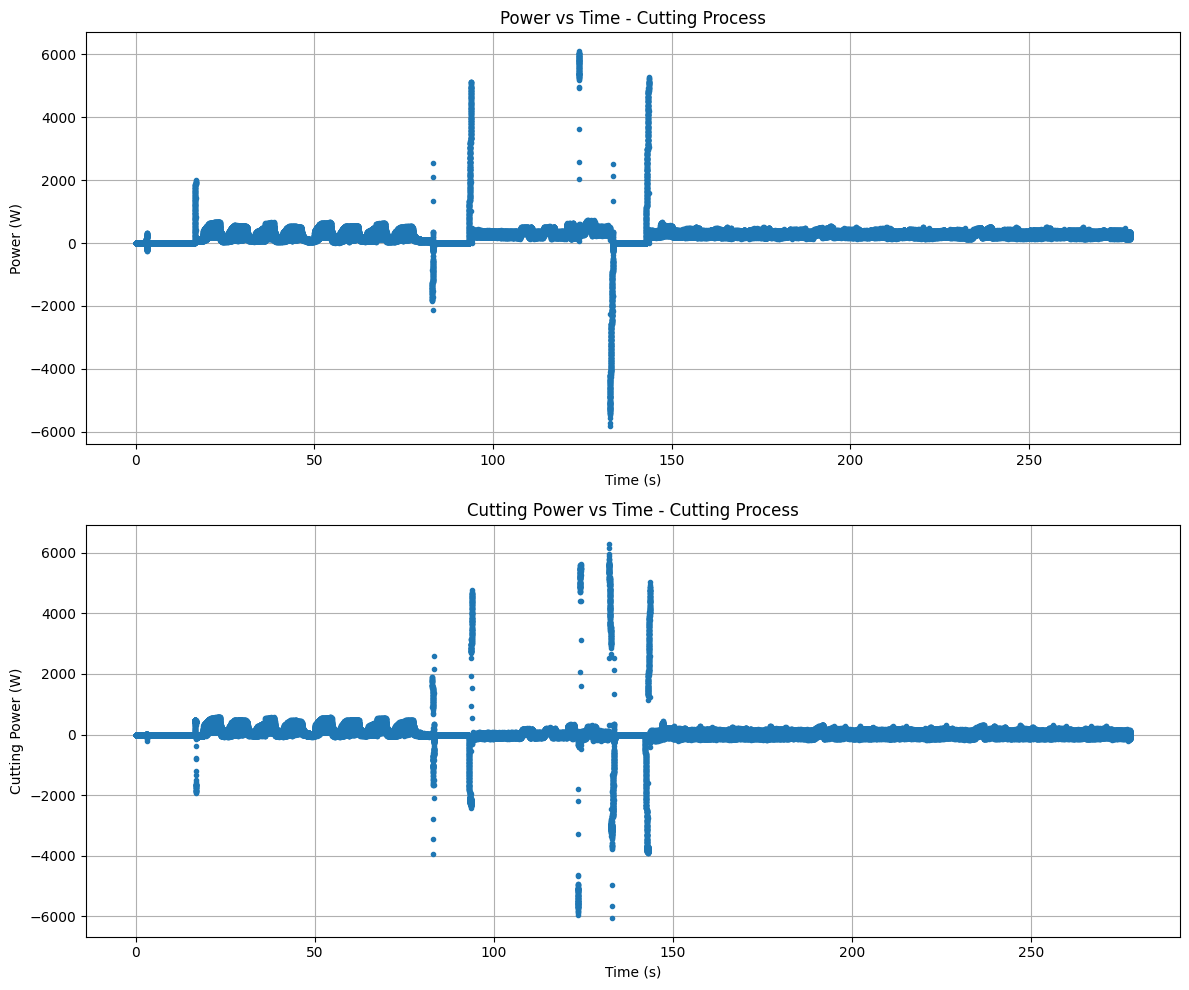

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(df5A1B['time'], df5A1B['power'], marker='.', linestyle='none')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Power (W)')
axes[0].set_title('Power vs Time - Cutting Process')
axes[0].grid(True)

axes[1].plot(df150['time'], df150['power'], marker='.', linestyle='none')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Cutting Power (W)')
axes[1].set_title('Cutting Power vs Time - Cutting Process')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Ignoring the power peaks, it's possible to observed that frequently the cutting power is lower than zero, which is physically impossible (it means that cutting produces energy). Probably there is an inconsistency between the two sessions. **For that reason the analysis will be performed on the total power of the cutting session.** Moreover, this approach can still be representative, since retaining the NON-cutting power simply results in a constant translation of the power values.

### Surface Milling

Surfacing interval (excluding power peaks) = $[18, 80]$ seconds.

In [6]:
# Redefinition of surfacing part
df150 = df5A1B[['time', 'power']].copy()    # entire cutting session
df150 = df150[(df150['time'] >= 18) & (df150['time'] <= 80)]

# Revolution counter (just in the surfacing interval!)
Trev = 60/N # (s) revolution period
df150['rev'] = ((df150['time'] - df150['time'].iloc[0])/Trev).astype(int)
df150.insert(0, 'rev', df150.pop('rev'))

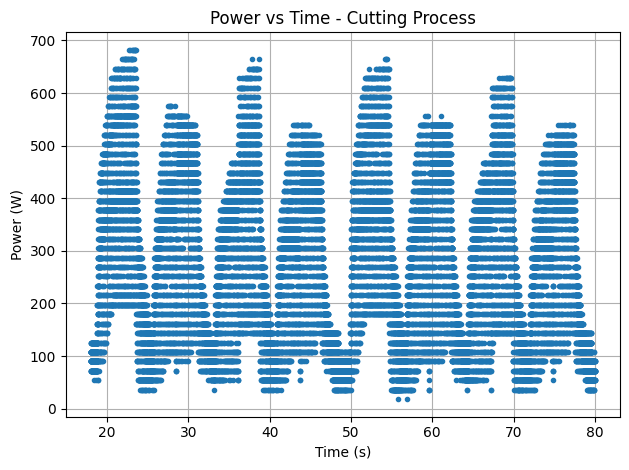

In [8]:
plt.plot(df150['time'], df150['power'], marker='.', linestyle='none')
plt.xlabel('Time (s)')
plt.ylabel('Power (W)')
plt.title('Power vs Time - Cutting Process')
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
stats = df150.groupby('rev')['power'].agg(
    mean_power='mean',
    min_power='min',
    max_power='max'
).reset_index()

pd.set_option('display.precision', 2)

stats.head(12).style.format("{:.2f}").set_caption("First 12 revolutions")


,rev,mean_power,min_power,max_power
0,0.00,97.84,71.81,125.67
1,1.00,96.49,71.81,125.67
2,2.00,94.36,71.81,125.67
3,3.00,98.29,71.81,125.67
4,4.00,94.82,71.81,125.67
5,5.00,93.80,53.86,125.67
6,6.00,95.15,71.81,125.67
7,7.00,92.98,71.81,125.67
8,8.00,92.90,53.86,125.67
9,9.00,101.27,71.81,161.57


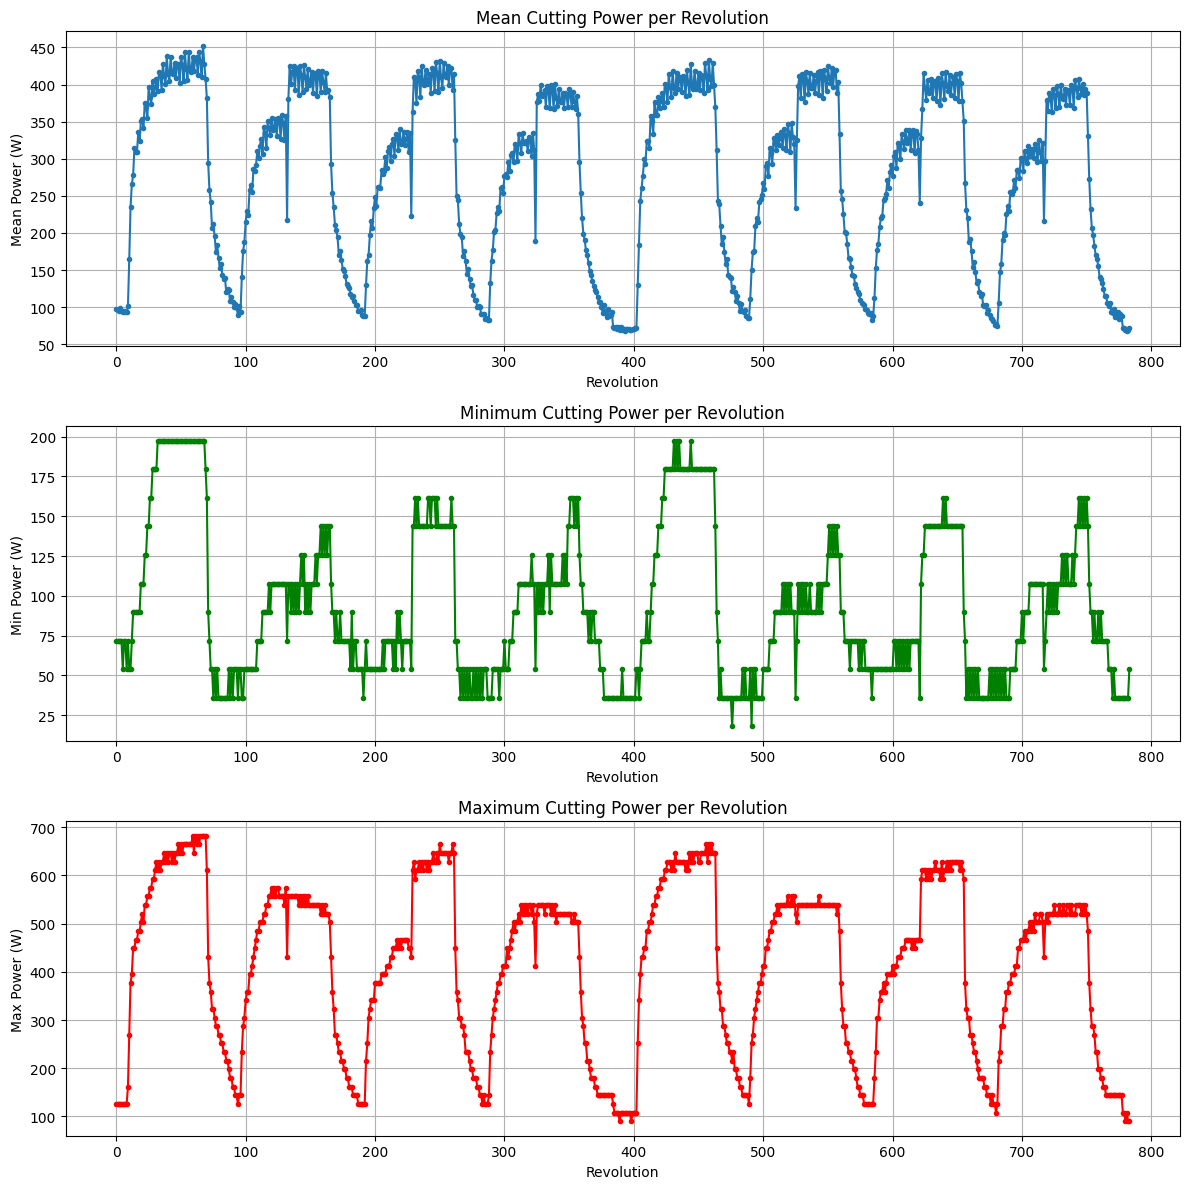

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
fig.subplots_adjust(hspace=0.4)

axes[0].plot(stats['rev'], stats['mean_power'], marker='.')
axes[0].set_xlabel('Revolution')
axes[0].set_ylabel('Mean Power (W)')
axes[0].set_title('Mean Cutting Power per Revolution')
axes[0].grid(True)

axes[1].plot(stats['rev'], stats['min_power'], marker='.', color='green')
axes[1].set_xlabel('Revolution')
axes[1].set_ylabel('Min Power (W)')
axes[1].set_title('Minimum Cutting Power per Revolution')
axes[1].grid(True)

axes[2].plot(stats['rev'], stats['max_power'], marker='.', color='red')
axes[2].set_xlabel('Revolution')
axes[2].set_ylabel('Max Power (W)')
axes[2].set_title('Maximum Cutting Power per Revolution')
axes[2].grid(True)

plt.tight_layout()
plt.show()


### Energy consumption per revolution

In order to evaluate the energy consumed in the $i$-th revolution, it has to be computed:
$$
E_i = \int_{t_{0_i}}^{t_{f_i}} P_i \, dt.
$$

Considering the discreet sample, it will be applied the trapezoidal rule:
$$
E_i = \sum_{j=i}^{i+n-1} \frac{P_j + P_{j+1}}{2} (t_{j+1}-t_j)
$$

where $n$ is the number of elements in the $i$-th revolution.

In [11]:
energy_per_rev = []

for rev_id, group in df150.groupby('rev'):
    t = group['time'].values
    p = group['power'].values
    
    dt = t[1:] - t[:-1]                  # Δt_j
    p_avg = (p[1:] + p[:-1]) / 2         # (P_j + P_{j+1})/2
    
    E = (p_avg * dt).sum()
    
    energy_per_rev.append([rev_id, E])

energy_per_rev = pd.DataFrame(energy_per_rev, columns=['rev', 'energy'])


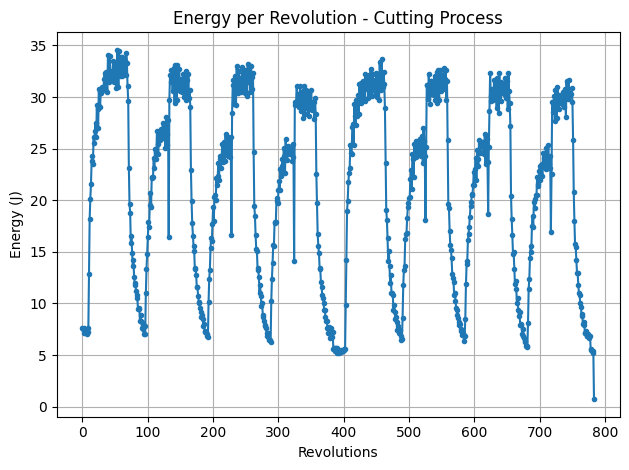

In [12]:
plt.plot(energy_per_rev['rev'], energy_per_rev['energy'], marker='.', linestyle='-')
plt.xlabel('Revolutions')
plt.ylabel('Energy (J)')
plt.title('Energy per Revolution - Cutting Process')
plt.grid(True)
plt.tight_layout()
plt.show()